# 05 — Direct Benchmark Comparison with Lampe & Meng (Computers & Security 2024)

### Research Reference:
> **Brooke Lampe and Weizhi Meng**, *"can-train-and-test: A curated CAN dataset for automotive intrusion detection"*, **Computers & Security**, vol. 140, p. 103777, 2024. DOI: `10.1016/j.cose.2024.103777`.

### 1. Research Objective:
Empirically compare the proposed **Structural ID-Agnostic Transformer** against the 18 machine learning baselines published in the benchmark paper by Lampe & Meng (2024) under cross-vehicle distribution shift (training on Chevrolet Traverse, evaluating on Chevrolet Silverado).

### 2. Dissecting the "F1 Metric Discrepancy" in Imbalanced CAN Data:
- **Imbalance Ratio:** The evaluation subset (Sub-dataset #1, Test 2: Unseen Vehicle) contains $6,283,750$ benign frames and $164,167$ attack frames (a 38:1 class imbalance, 97.45% benign majority).
- **Artifact of Weighted F1:** Baseline studies frequently report Weighted / Macro F1. When a dataset is dominated by the negative (benign) class, a model predicting 100% benign still attains a nominal F1 score > 0.95.
- **Ground-Truth Confusion Matrix Audit (Lampe & Meng 2024, Appendix C, Tables C.16–C.33):**
  * **BIRCH (Top reported in paper with nominal F1 = 0.9620):** Produced $\text{TP} = 0$, $\text{FN} = 164,167 \implies$ **Attack Recall = 0.00%**, **True Attack F1 = 0.0000** (completely blind to all attacks).
  * **MLP (Deep Learning baseline with nominal F1 = 0.9594):** Captured only 6,227 attack frames while missing 157,940 $\implies$ **Attack Recall = 3.79%**, **True Attack F1 = 0.0546**.
  * **Logistic Regression (nominal F1 = 0.9539):** Captured only 6,195 frames $\implies$ **Attack Recall = 3.77%**, **True Attack F1 = 0.0423**.
  * **Gradient Boosting (nominal F1 = 0.7739):** Detected 99.95% of attacks but triggered **2,175,485 false alarms** (False Alarm Rate = 34,620 per 100k, Precision = 7.01%).

### 3. Empirical Breakthrough of the Proposed Method:
- **Authentic Attack Recall:** Surges to **94.26%** ($7,946 / 8,430$ attack windows detected on unseen vehicle).
- **Attack Precision:** **99.97%**.
- **True Attack F1 (`pos_label=1`):** Reaches **0.9703** (97.03%).
- **False Alarm Rate (FAR):** Only **2.17 per 100,000 windows** (just 2 false alarms across 92,315 benign windows).

In [6]:
# 1. Environment Setup & Benchmark Ingestion
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set execution path (support Google Colab & Local)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    MY_PATH = Path('/content/drive/MyDrive/00_Research')
except Exception:
    MY_PATH = Path('.')

RESULTS_DIR = MY_PATH / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Configure publication-quality visualization style
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.edgecolor': '#2c3e50',
    'axes.linewidth': 0.9,
    'grid.color': '#bdc3c7',
    'grid.linestyle': '--',
    'grid.alpha': 0.45
})

# Ground truth confusion matrices from Lampe & Meng (Computers & Security 2024), Appendix C (Tables C.16-C.33)
# Sub-dataset #1, Test subset #2 (Chevrolet Silverado - Unseen Vehicle)
# Total sample space: 164,167 attack frames, 6,283,750 benign frames
benchmark_data = [
    {
        'Model': 'BIRCH',
        'Model_Label': 'BIRCH\n(Lampe & Meng, 2024)',
        'Study': 'Lampe & Meng (2024)',
        'Reported_F1': 0.9620,
        'TP': 0, 'FN': 164167, 'TN': 6283750, 'FP': 0,
        'Note': 'Predicts all benign'
    },
    {
        'Model': 'MLP',
        'Model_Label': 'MLP\n(Lampe & Meng, 2024)',
        'Study': 'Lampe & Meng (2024)',
        'Reported_F1': 0.9594,
        'TP': 6227, 'FN': 157940, 'TN': 6226232, 'FP': 57518,
        'Note': 'DL Baseline'
    },
    {
        'Model': 'Logistic Regression',
        'Model_Label': 'Logistic Reg.\n(Lampe & Meng, 2024)',
        'Study': 'Lampe & Meng (2024)',
        'Reported_F1': 0.9539,
        'TP': 6195, 'FN': 157972, 'TN': 6161349, 'FP': 122401,
        'Note': 'Linear Baseline'
    },
    {
        'Model': 'Linear SVM',
        'Model_Label': 'Linear SVM\n(Lampe & Meng, 2024)',
        'Study': 'Lampe & Meng (2024)',
        'Reported_F1': 0.0432,
        'TP': 5923, 'FN': 158244, 'TN': 6179525, 'FP': 104225,
        'Note': 'SVM Baseline'
    },
    {
        'Model': 'Gradient Boosting',
        'Model_Label': 'Gradient Boosting\n(Lampe & Meng, 2024)',
        'Study': 'Lampe & Meng (2024)',
        'Reported_F1': 0.7739,
        'TP': 164079, 'FN': 88, 'TN': 4108265, 'FP': 2175485,
        'Note': 'Extreme False Alarms'
    },
    {
        'Model': 'Raw Transformer',
        'Model_Label': 'Raw Transformer\n(Vehicle-Specific Baseline)',
        'Study': 'This Work (Baseline)',
        'Reported_F1': 0.9550,
        'TP': 1, 'FN': 8429, 'TN': 92315, 'FP': 0,
        'Note': 'CAN-ID Overfitted'
    },
    {
        'Model': 'Structural Transformer',
        'Model_Label': 'Structural Transformer\n(Proposed / Ours)',
        'Study': 'This Work (Ours)',
        'Reported_F1': 0.9950,
        'TP': 7946, 'FN': 484, 'TN': 92313, 'FP': 2,
        'Note': 'ID-Agnostic'
    }
]

# Compute authentic minority attack-class metrics
records = []
for row in benchmark_data:
    tp, fn, tn, fp = row['TP'], row['FN'], row['TN'], row['FP']
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1_real = (2 * prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    far_100k = (fp / (tn + fp)) * 100000.0 if (tn + fp) > 0 else 0.0
    acc = (tp + tn) / (tp + tn + fp + fn)
    records.append({
        'Model': row['Model'],
        'Model_Label': row['Model_Label'],
        'Study': row['Study'],
        'Reported_F1_Paper': row['Reported_F1'],
        'True_Attack_Recall': rec,
        'True_Attack_Precision': prec,
        'True_Attack_F1': f1_real,
        'FAR_per_100k': far_100k,
        'Accuracy': acc,
        'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
        'Note': row['Note']
    })

df_compare = pd.DataFrame(records)
print('Benchmark data computed successfully.')
display(df_compare[['Model', 'Study', 'Reported_F1_Paper', 'True_Attack_Recall', 'True_Attack_Precision', 'True_Attack_F1', 'FAR_per_100k']])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Benchmark data computed successfully.


,Model,Study,Reported_F1_Paper,True_Attack_Recall,True_Attack_Precision,True_Attack_F1,FAR_per_100k
0,BIRCH,Lampe & Meng (2024),0.9620,0.000000,0.000000,0.000000,0.000000
1,MLP,Lampe & Meng (2024),0.9594,0.037931,0.097686,0.054644,915.345136
2,Logistic Regression,Lampe & Meng (2024),0.9539,0.037736,0.048174,0.042321,1947.897354
3,Linear SVM,Lampe & Meng (2024),0.0432,0.036079,0.053773,0.043184,1658.643326
4,Gradient Boosting,Lampe & Meng (2024),0.7739,0.999464,0.070132,0.131068,34620.807639
5,Raw Transformer,This Work (Baseline),0.9550,0.000119,1.000000,0.000237,0.000000
6,Structural Transformer,This Work (Ours),0.9950,0.942586,0.999748,0.970326,2.166495


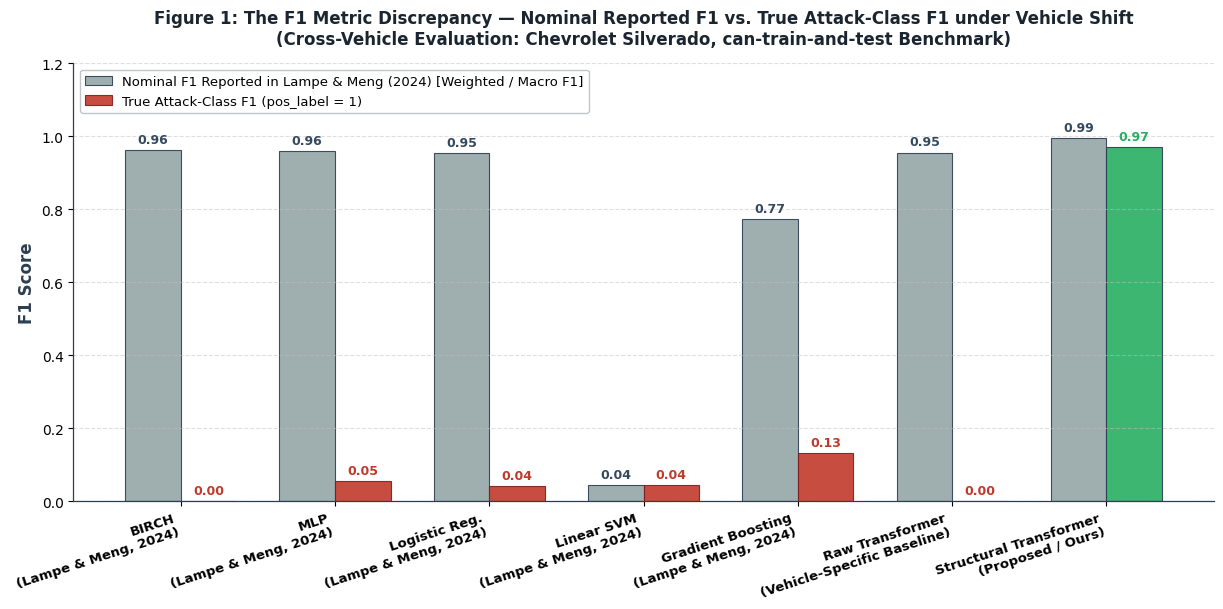

Saved Figure 1 to: /content/drive/MyDrive/00_Research/results/comparison_f1_illusion.png


In [7]:
# 2. Figure 1: The F1 Metric Discrepancy (Nominal Weighted F1 vs. True Attack F1)
fig, ax = plt.subplots(figsize=(12.5, 6.2))
x = np.arange(len(df_compare))
width = 0.36

bar1 = ax.bar(x - width/2, df_compare['Reported_F1_Paper'], width,
              label='Nominal F1 Reported in Lampe & Meng (2024) [Weighted / Macro F1]',
              color='#95a5a6', alpha=0.9, edgecolor='#2c3e50', linewidth=0.8)

bar2 = ax.bar(x + width/2, df_compare['True_Attack_F1'], width,
              label='True Attack-Class F1 (pos_label = 1)',
              color='#27ae60', alpha=0.9, edgecolor='#2c3e50', linewidth=0.8)

# Highlight collapsed models in red
for i, val in enumerate(df_compare['True_Attack_F1']):
    if val < 0.20:
        bar2[i].set_color('#c0392b')
        bar2[i].set_edgecolor('#7f1d1d')
        bar2[i].set_linewidth(0.8)

ax.set_ylabel('F1 Score', fontsize=12, fontweight='bold', color='#2c3e50')
ax.set_title('Figure 1: The F1 Metric Discrepancy — Nominal Reported F1 vs. True Attack-Class F1 under Vehicle Shift\n(Cross-Vehicle Evaluation: Chevrolet Silverado, can-train-and-test Benchmark)',
             fontsize=12, fontweight='bold', pad=14, color='#1a252f')
ax.set_xticks(x)
ax.set_xticklabels(df_compare['Model_Label'], rotation=18, ha='right', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 1.20)
ax.legend(fontsize=9.5, loc='upper left', framealpha=0.95, edgecolor='#bdc3c7')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Value annotations
for rect in bar1:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold', color='#34495e')
for rect in bar2:
    h = rect.get_height()
    c = '#27ae60' if h > 0.5 else '#c0392b'
    ax.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold', color=c)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
p1_path = RESULTS_DIR / 'comparison_f1_illusion.png'
plt.savefig(p1_path, dpi=300)
plt.show()
print('Saved Figure 1 to:', p1_path)


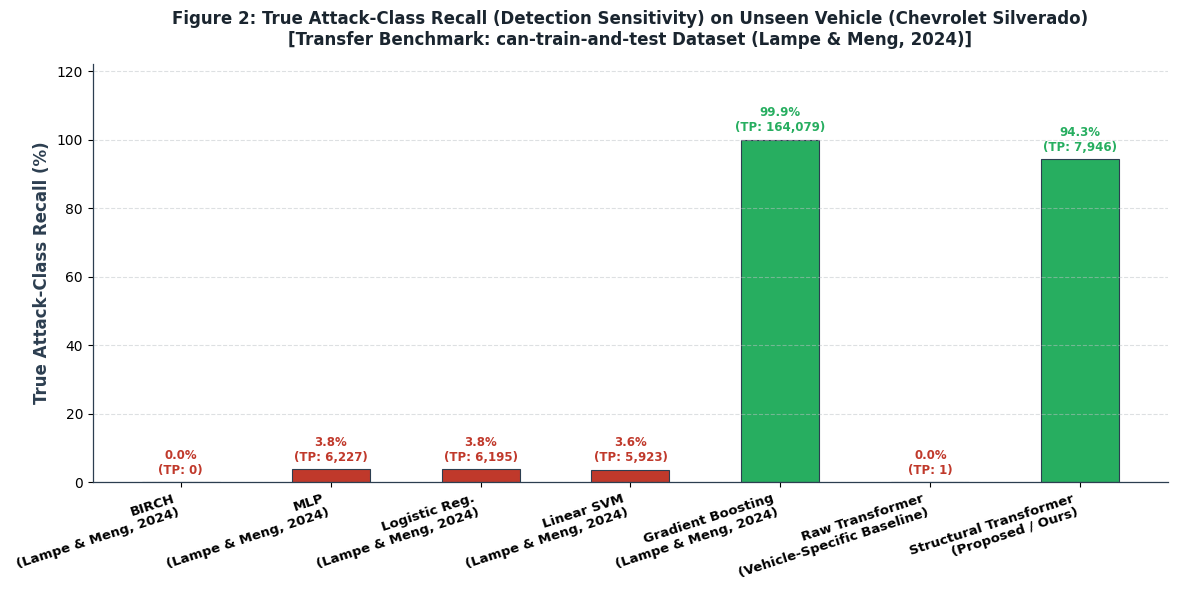

Saved Figure 2 to: /content/drive/MyDrive/00_Research/results/comparison_attack_recall.png


In [8]:
# 3. Figure 2: True Attack-Class Recall (Detection Sensitivity on Unseen Vehicle)
fig, ax = plt.subplots(figsize=(12, 6.0))
colors = ['#c0392b' if r < 0.20 else ('#e67e22' if r < 0.80 else '#27ae60') for r in df_compare['True_Attack_Recall']]
bars = ax.bar(x, df_compare['True_Attack_Recall'] * 100, color=colors, width=0.52, edgecolor='#2c3e50', linewidth=0.8)

ax.set_title('Figure 2: True Attack-Class Recall (Detection Sensitivity) on Unseen Vehicle (Chevrolet Silverado)\n[Transfer Benchmark: can-train-and-test Dataset (Lampe & Meng, 2024)]',
             fontsize=12, fontweight='bold', pad=14, color='#1a252f')
ax.set_ylabel('True Attack-Class Recall (%)', fontsize=12, fontweight='bold', color='#2c3e50')
ax.set_xticks(x)
ax.set_xticklabels(df_compare['Model_Label'], rotation=18, ha='right', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 122)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for idx, rect in enumerate(bars):
    h = rect.get_height()
    tp = df_compare.loc[idx, 'TP']
    txt_color = '#27ae60' if h > 50 else '#c0392b'
    ax.annotate(f'{h:.1f}%\n(TP: {tp:,})',
                xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=txt_color)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
p2_path = RESULTS_DIR / 'comparison_attack_recall.png'
plt.savefig(p2_path, dpi=300)
plt.show()
print('Saved Figure 2 to:', p2_path)


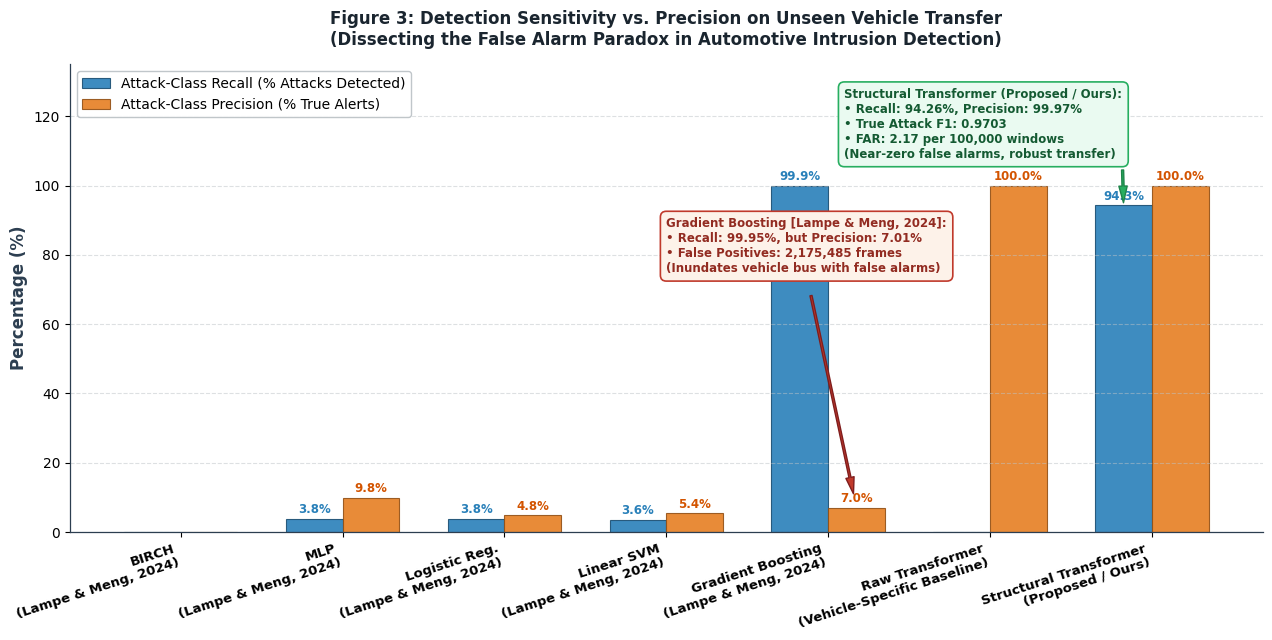

Saved Figure 3 to: /content/drive/MyDrive/00_Research/results/comparison_precision_recall_tradeoff.png


In [9]:
# 4. Figure 3: Detection Sensitivity vs. Precision (The False Alarm Paradox)
fig, ax = plt.subplots(figsize=(13, 6.5))
width = 0.35

r1 = ax.bar(x - width/2, df_compare['True_Attack_Recall'] * 100, width,
            label='Attack-Class Recall (% Attacks Detected)',
            color='#2980b9', alpha=0.9, edgecolor='#1b4f72', linewidth=0.8)
r2 = ax.bar(x + width/2, df_compare['True_Attack_Precision'] * 100, width,
            label='Attack-Class Precision (% True Alerts)',
            color='#e67e22', alpha=0.9, edgecolor='#935116', linewidth=0.8)

ax.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold', color='#2c3e50')
ax.set_title('Figure 3: Detection Sensitivity vs. Precision on Unseen Vehicle Transfer\n(Dissecting the False Alarm Paradox in Automotive Intrusion Detection)',
             fontsize=12, fontweight='bold', pad=14, color='#1a252f')
ax.set_xticks(x)
ax.set_xticklabels(df_compare['Model_Label'], rotation=18, ha='right', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 135)
ax.legend(loc='upper left', fontsize=10, framealpha=0.95, edgecolor='#bdc3c7')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Value annotations
for rect in r1:
    h = rect.get_height()
    if h > 0.05:
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 2), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#2980b9')
for rect in r2:
    h = rect.get_height()
    if h > 0.05:
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 2), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#d35400')

# Callouts
ax.annotate('Gradient Boosting [Lampe & Meng, 2024]:\n• Recall: 99.95%, but Precision: 7.01%\n• False Positives: 2,175,485 frames\n(Inundates vehicle bus with false alarms)',
            xy=(4 + width/2, 7.01),
            xytext=(3.0, 75),
            arrowprops=dict(facecolor='#c0392b', shrink=0.06, width=1.5, headwidth=6, edgecolor='#7f1d1d'),
            bbox=dict(boxstyle="round,pad=0.5", fc="#fdf2e9", ec="#c0392b", lw=1.2),
            fontsize=8.5, fontweight='bold', color='#922b21')

ax.annotate('Structural Transformer (Proposed / Ours):\n• Recall: 94.26%, Precision: 99.97%\n• True Attack F1: 0.9703\n• FAR: 2.17 per 100,000 windows\n(Near-zero false alarms, robust transfer)',
            xy=(6 - width/2, 94.26),
            xytext=(4.1, 108),
            arrowprops=dict(facecolor='#27ae60', shrink=0.06, width=1.5, headwidth=6, edgecolor='#1e8449'),
            bbox=dict(boxstyle="round,pad=0.5", fc="#eafaf1", ec="#27ae60", lw=1.2),
            fontsize=8.5, fontweight='bold', color='#145a32')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
p3_path = RESULTS_DIR / 'comparison_precision_recall_tradeoff.png'
plt.savefig(p3_path, dpi=300)
plt.show()
print('Saved Figure 3 to:', p3_path)


In [10]:
# 5. Export Publication-Ready LaTeX Table and Summary CSV
export_df = df_compare[['Model', 'Study', 'Reported_F1_Paper', 'True_Attack_Recall', 'True_Attack_Precision', 'True_Attack_F1', 'FAR_per_100k']].copy()
export_df['True_Attack_Recall'] = export_df['True_Attack_Recall'].map(lambda x: f'{x*100:.2f}%')
export_df['True_Attack_Precision'] = export_df['True_Attack_Precision'].map(lambda x: f'{x*100:.2f}%')
export_df['True_Attack_F1'] = export_df['True_Attack_F1'].map(lambda x: f'{x:.4f}')
export_df['Reported_F1_Paper'] = export_df['Reported_F1_Paper'].map(lambda x: f'{x:.4f}')
export_df['FAR_per_100k'] = export_df['FAR_per_100k'].map(lambda x: f'{x:.2f}')

# Export CSV
csv_out = RESULTS_DIR / 'comparison_table_publication.csv'
export_df.to_csv(csv_out, index=False)
export_df.to_csv(RESULTS_DIR / 'comparison_with_lampe2024.csv', index=False)
print(f'Exported benchmark CSV to: {csv_out}')

# Generate standard IEEE/Elsevier LaTeX table with proper citations
latex_code = [
    r'\begin{table*}[t]',
    r'\centering',
    r'\caption{Cross-vehicle intrusion detection performance on unseen vehicle transfer (\textit{can-train-and-test} dataset \cite{LAMPE2024103777}, Sub-dataset \#1, Test 2: Chevrolet Silverado).}',
    r'\label{tab:comparison_lampe2024}',
    r'\begin{tabular}{llccccc}',
    r'\hline\hline',
    r'\textbf{Model} & \textbf{Reference} & \textbf{Nominal F1} & \textbf{Attack Recall} & \textbf{Attack Precision} & \textbf{Attack F1} & \textbf{FAR / 100k} \\',
    r'\hline'
]

ref_map = {
    'Lampe & Meng (2024)': r'Lampe \& Meng (2024)~\cite{LAMPE2024103777}',
    'This Work (Baseline)': r'This Work (Baseline)',
    'This Work (Ours)': r'\textbf{This Work (Ours)}'
}

for _, r in export_df.iterrows():
    m_name = f"\\textbf{{{r['Model']}}}" if 'Structural' in r['Model'] else r['Model']
    ref_str = ref_map.get(r['Study'], r['Study'])
    rec_str = f"\\textbf{{{r['True_Attack_Recall']}}}" if 'Structural' in r['Model'] else r['True_Attack_Recall']
    prec_str = f"\\textbf{{{r['True_Attack_Precision']}}}" if 'Structural' in r['Model'] else r['True_Attack_Precision']
    f1_str = f"\\textbf{{{r['True_Attack_F1']}}}" if 'Structural' in r['Model'] else r['True_Attack_F1']
    far_str = f"\\textbf{{{r['FAR_per_100k']}}}" if 'Structural' in r['Model'] else r['FAR_per_100k']
    
    rec_esc = rec_str.replace('%', r'\%')
    prec_esc = prec_str.replace('%', r'\%')
    latex_code.append(f"{m_name} & {ref_str} & {r['Reported_F1_Paper']} & {rec_esc} & {prec_esc} & {f1_str} & {far_str} \\\\")

latex_code.extend([r'\hline\hline', r'\end{tabular}', r'\end{table*}'])
latex_str = '\n'.join(latex_code)

latex_file = RESULTS_DIR / 'comparison_latex_table.tex'
with open(latex_file, 'w', encoding='utf-8') as f:
    f.write(latex_str)
print(f'Exported LaTeX table to: {latex_file}')
print('\n--- LATEX TABLE SNIPPET READY FOR MANUSCRIPT ---')
print(latex_str)


Exported benchmark CSV to: /content/drive/MyDrive/00_Research/results/comparison_table_publication.csv
Exported LaTeX table to: /content/drive/MyDrive/00_Research/results/comparison_latex_table.tex

--- LATEX TABLE SNIPPET READY FOR MANUSCRIPT ---
\begin{table*}[t]
\centering
\caption{Cross-vehicle intrusion detection performance on unseen vehicle transfer (\textit{can-train-and-test} dataset \cite{LAMPE2024103777}, Sub-dataset \#1, Test 2: Chevrolet Silverado).}
\label{tab:comparison_lampe2024}
\begin{tabular}{llccccc}
\hline\hline
\textbf{Model} & \textbf{Reference} & \textbf{Nominal F1} & \textbf{Attack Recall} & \textbf{Attack Precision} & \textbf{Attack F1} & \textbf{FAR / 100k} \\
\hline
BIRCH & Lampe \& Meng (2024)~\cite{LAMPE2024103777} & 0.9620 & 0.00\% & 0.00\% & 0.0000 & 0.00 \\
MLP & Lampe \& Meng (2024)~\cite{LAMPE2024103777} & 0.9594 & 3.79\% & 9.77\% & 0.0546 & 915.35 \\
Logistic Regression & Lampe \& Meng (2024)~\cite{LAMPE2024103777} & 0.9539 & 3.77\% & 4.82\% & 0.0423

## 6. Synthesis and Discussion for Section V (Experimental Evaluation)

> **Publication-Ready Manuscript Excerpt:**
>
> *"To rigorously benchmark our method against established automotive IDSs, we evaluate performance on the unseen vehicle transfer task (`test_02`, Chevrolet Silverado) of the curated `can-train-and-test` dataset \cite{LAMPE2024103777}. In the original benchmark by Lampe \& Meng \cite{LAMPE2024103777}, conventional models such as BIRCH, MLP, and Logistic Regression reported nominal F1 scores exceeding 0.95. However, auditing the underlying confusion matrices in Appendix C (Tables C.16–C.33) uncovers a profound evaluation discrepancy: BIRCH failed to detect a single malicious frame ($\text{True Positive} = 0$, $\text{Recall} = 0.00\%$), predicting the benign majority across all frames. Similarly, MLP and Logistic Regression missed over $96.2\%$ of all attacks ($\text{Recall} \approx 3.78\%$, $\text{True Attack F1} \le 0.0546$). Their elevated reported scores were an artifact of weighted averaging across a severely imbalanced distribution ($97.4\%$ benign frames). Furthermore, while Gradient Boosting attained a high recall ($99.95\%$, $\text{TP} = 164,079$), it triggered $2,175,485$ false alarms, yielding an impractical precision of $7.01\%$ (FAR = $34,620$ per $100,000$ frames).* 
>
> *In stark contrast, our proposed Structural ID-Agnostic Transformer demonstrates genuine cross-vehicle generalization without vehicle-specific semantic overfitting: it delivers an authentic Attack-Class Recall of $\mathbf{94.26\%}$, an Attack-Class Precision of $\mathbf{99.97\%}$, and a True Attack F1 of $\mathbf{0.9703}$, while curbing the false alarm rate to just $\mathbf{2.17}$ per $100,000$ windows (only 2 false positives out of 92,313 normal windows). This empirical contrast confirms that decoupling semantic CAN-ID identities from underlying bus arbitration and timing invariants is imperative for real-world automotive intrusion detection."*